### 1 Downloading LST from MOD11A1

In [3]:
import ee
import geemap
import os

ee.Initialize()

# ======================
# ROI
# ======================
roi = ee.FeatureCollection(
    "projects/lithe-inscriber-448612-q7/assets/tekeze"
)

# ======================
# MODIS DAILY LST
# ======================
col = (ee.ImageCollection("MODIS/061/MOD11A1")
       .select("LST_Day_1km")
       .filterDate("2000-01-01", "2010-12-31")
       .filterBounds(roi)
)

# ======================
# SCALE + CONVERT FUNCTION
# ======================
def prep(img):
    lst = img.select("LST_Day_1km")

    # scale factor (Kelvin)
    lst = lst.multiply(0.02)

    # Kelvin → Celsius
    lst = lst.subtract(273.15)

    return lst.copyProperties(img, ["system:time_start"])

col = col.map(prep)

# ======================
# FUNCTION: MONTHLY MEAN
# ======================
def monthly_mean(year, month):
    start = ee.Date.fromYMD(year, month, 1)
    end = start.advance(1, "month")

    img = col.filterDate(start, end).mean()

    return img.set("system:time_start", start.millis())

# ======================
# BUILD MONTHLY COLLECTION
# ======================
years = ee.List.sequence(2000, 2010)
months = ee.List.sequence(1, 12)

monthly_list = years.map(
    lambda y: months.map(
        lambda m: monthly_mean(y, m)
    )
).flatten()

monthly_ic = ee.ImageCollection(monthly_list)

# ======================
# CONVERT TO LIST
# ======================
size = monthly_ic.size().getInfo()
images = monthly_ic.toList(size)

print("Total monthly LST images:", size)

# ======================
# EXPORT LOOP (same style as NDVI)
# ======================
for i in range(size):

    img = ee.Image(images.get(i))

    date = ee.Date(img.get("system:time_start")).format("YYYY_MM").getInfo()

    filename = f"LST_{date}"

    task = ee.batch.Export.image.toDrive(
        image=img.clip(roi),
        description=filename,
        folder="GEE_LST_2000_2010_4326",
        fileNamePrefix=filename,
        region=roi.geometry(),
        scale=1000,
        crs="EPSG:4326",
        maxPixels=1e13
    )

    task.start()
    print("Started:", filename)

print("All LST export tasks started ✔")

Total monthly LST images: 132
Started: LST_2000_01
Started: LST_2000_02
Started: LST_2000_03
Started: LST_2000_04
Started: LST_2000_05
Started: LST_2000_06
Started: LST_2000_07
Started: LST_2000_08
Started: LST_2000_09
Started: LST_2000_10
Started: LST_2000_11
Started: LST_2000_12
Started: LST_2001_01
Started: LST_2001_02
Started: LST_2001_03
Started: LST_2001_04
Started: LST_2001_05
Started: LST_2001_06
Started: LST_2001_07
Started: LST_2001_08
Started: LST_2001_09
Started: LST_2001_10
Started: LST_2001_11
Started: LST_2001_12
Started: LST_2002_01
Started: LST_2002_02
Started: LST_2002_03
Started: LST_2002_04
Started: LST_2002_05
Started: LST_2002_06
Started: LST_2002_07
Started: LST_2002_08
Started: LST_2002_09
Started: LST_2002_10
Started: LST_2002_11
Started: LST_2002_12
Started: LST_2003_01
Started: LST_2003_02
Started: LST_2003_03
Started: LST_2003_04
Started: LST_2003_05
Started: LST_2003_06
Started: LST_2003_07
Started: LST_2003_08
Started: LST_2003_09
Started: LST_2003_10
Star

### visualize 2011

Files found: 12


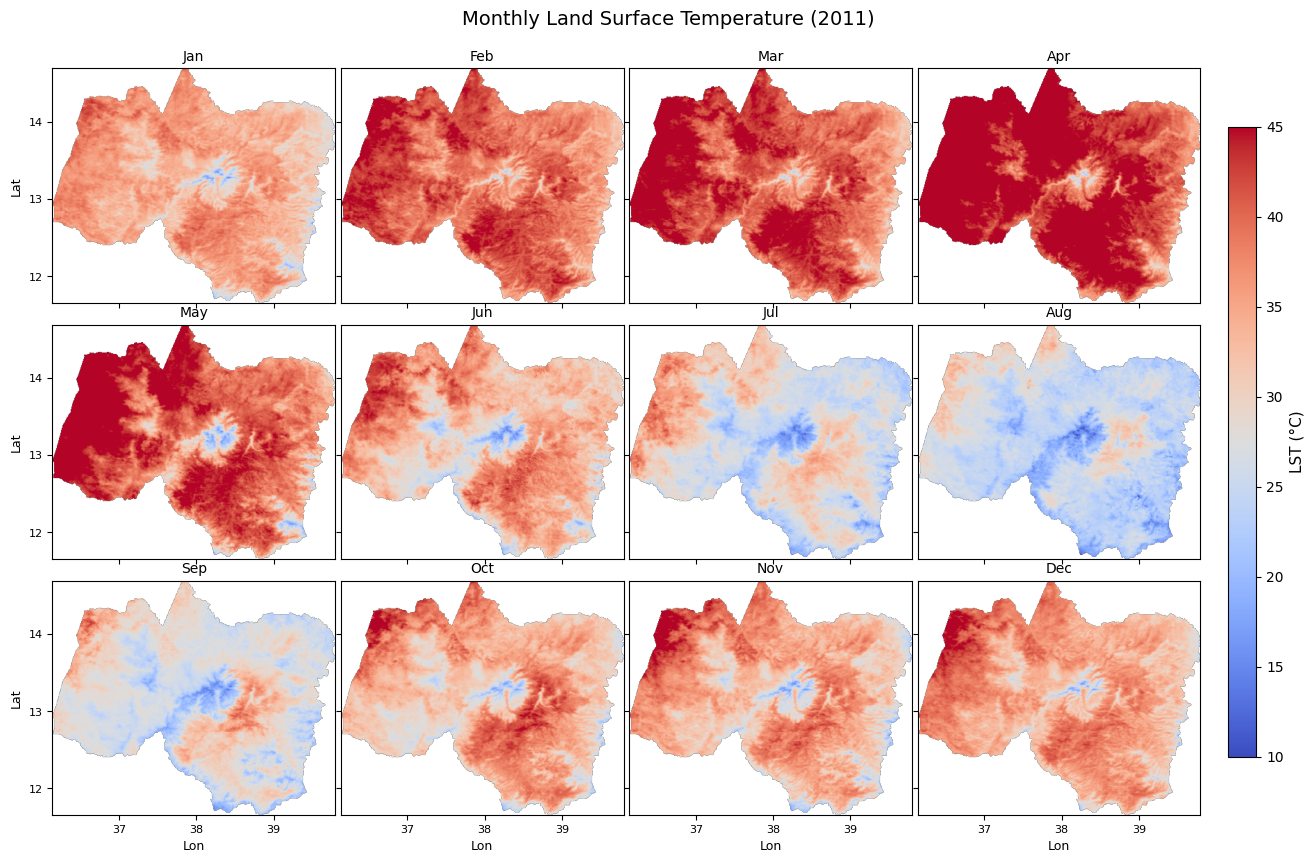

In [4]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ======================
# Folder
# ======================
folder = r"C:\Users\gerii\Documents\projects\tekeze\LST"

files = sorted([
    f for f in os.listdir(folder)
    if f.startswith("LST_2011") and f.endswith(".tif")
])

print("Files found:", len(files))

# ======================
# Figure
# ======================
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
axes = axes.flatten()

months = ["Jan","Feb","Mar","Apr","May","Jun",
          "Jul","Aug","Sep","Oct","Nov","Dec"]

# ======================
# LST range (adjust if needed)
# ======================
vmin = 10   # typical lower bound (°C)
vmax = 45   # typical upper bound (°C)

# ======================
# Plot loop
# ======================
for i, f in enumerate(files):

    path = os.path.join(folder, f)

    with rasterio.open(path) as src:
        data = src.read(1).astype("float32")

        # mask unrealistic values
        data[data < -50] = np.nan

        bounds = src.bounds
        extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]

    ax = axes[i]

    im = ax.imshow(
        data,
        extent=extent,
        origin="upper",
        cmap="coolwarm",   # good for temperature
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(months[i], fontsize=10)

    # ======================
    # 1-degree ticks
    # ======================
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.tick_params(labelsize=8)

    # ======================
    # Axis control
    # ======================
    row = i // 4
    col = i % 4

    if col == 0:
        ax.set_ylabel("Lat", fontsize=9)
    else:
        ax.set_yticklabels([])

    if row == 2:
        ax.set_xlabel("Lon", fontsize=9)
    else:
        ax.set_xticklabels([])

# ======================
# Remove unused axes
# ======================
for j in range(len(files), 12):
    axes[j].axis("off")

# ======================
# Tight layout
# ======================
plt.subplots_adjust(
    left=0.06,
    right=0.88,
    top=0.92,
    bottom=0.08,
    wspace=0.02,
    hspace=0.05
)

# ======================
# Colorbar
# ======================
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("LST (°C)", fontsize=11)

# ======================
# Title
# ======================
plt.suptitle("Monthly Land Surface Temperature (2011)", fontsize=14)

# ======================
# Save
# ======================
fig.canvas.draw()
fig.savefig(
    r"C:\Users\gerii\Documents\projects\tekeze\LST\LST_2011_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

### TCI 

In [7]:
import os
import numpy as np
import rasterio

# ======================
# Input / Output folders
# ======================
in_folder = r"C:\Users\gerii\Documents\projects\tekeze\LST"
out_folder = r"C:\Users\gerii\Documents\projects\tekeze\TCI"

os.makedirs(out_folder, exist_ok=True)

# ======================
# Get LST files
# ======================
files = sorted([
    f for f in os.listdir(in_folder)
    if f.startswith("LST_") and f.endswith(".tif")
])

print("Total LST files:", len(files))

# ======================
# Read stack
# ======================
stack = []
meta = None

for f in files:
    path = os.path.join(in_folder, f)

    with rasterio.open(path) as src:
        data = src.read(1).astype("float32")

        # remove unrealistic values
        data[data < -50] = np.nan

        stack.append(data)

        if meta is None:
            meta = src.meta.copy()

stack = np.array(stack)  # (time, rows, cols)

print("Stack shape:", stack.shape)

# ======================
# Compute min/max (per pixel)
# ======================
lst_min = np.nanmin(stack, axis=0)
lst_max = np.nanmax(stack, axis=0)

den = lst_max - lst_min
den[den == 0] = np.nan

print("Min/Max computed ✔")

# ======================
# Update metadata
# ======================
meta.update(dtype="float32", count=1)

# ======================
# Compute TCI
# ======================
for i, f in enumerate(files):

    lst = stack[i]

    # TCI formula
    tci = (lst_max - lst) / den

    # clip to valid range
    tci = np.clip(tci, 0, 1)

    # convert to % optional
    #tci = tci * 100

    # output name
    out_name = f.replace("LST_", "TCI_")
    out_path = os.path.join(out_folder, out_name)

    # save GeoTIFF
    with rasterio.open(out_path, "w", **meta) as dst:
        dst.write(tci.astype("float32"), 1)

    print("Saved:", out_name)

print("All TCI files created successfully ✔")

Total LST files: 311
Stack shape: (311, 337, 407)
Min/Max computed ✔


C:\Users\geri geri\AppData\Local\Temp\ipykernel_11448\1349493520.py:50: RuntimeWarning: All-NaN slice encountered
  lst_min = np.nanmin(stack, axis=0)
C:\Users\geri geri\AppData\Local\Temp\ipykernel_11448\1349493520.py:51: RuntimeWarning: All-NaN slice encountered
  lst_max = np.nanmax(stack, axis=0)


Saved: TCI_2000_02.tif
Saved: TCI_2000_03.tif
Saved: TCI_2000_04.tif
Saved: TCI_2000_05.tif
Saved: TCI_2000_06.tif
Saved: TCI_2000_07.tif
Saved: TCI_2000_08.tif
Saved: TCI_2000_09.tif
Saved: TCI_2000_10.tif
Saved: TCI_2000_11.tif
Saved: TCI_2000_12.tif
Saved: TCI_2001_01.tif
Saved: TCI_2001_02.tif
Saved: TCI_2001_03.tif
Saved: TCI_2001_04.tif
Saved: TCI_2001_05.tif
Saved: TCI_2001_06.tif
Saved: TCI_2001_07.tif
Saved: TCI_2001_08.tif
Saved: TCI_2001_09.tif
Saved: TCI_2001_10.tif
Saved: TCI_2001_11.tif
Saved: TCI_2001_12.tif
Saved: TCI_2002_01.tif
Saved: TCI_2002_02.tif
Saved: TCI_2002_03.tif
Saved: TCI_2002_04.tif
Saved: TCI_2002_05.tif
Saved: TCI_2002_06.tif
Saved: TCI_2002_07.tif
Saved: TCI_2002_08.tif
Saved: TCI_2002_09.tif
Saved: TCI_2002_10.tif
Saved: TCI_2002_11.tif
Saved: TCI_2002_12.tif
Saved: TCI_2003_01.tif
Saved: TCI_2003_02.tif
Saved: TCI_2003_03.tif
Saved: TCI_2003_04.tif
Saved: TCI_2003_05.tif
Saved: TCI_2003_06.tif
Saved: TCI_2003_07.tif
Saved: TCI_2003_08.tif
Saved: TCI_

### visualize TCI

Files found: 12


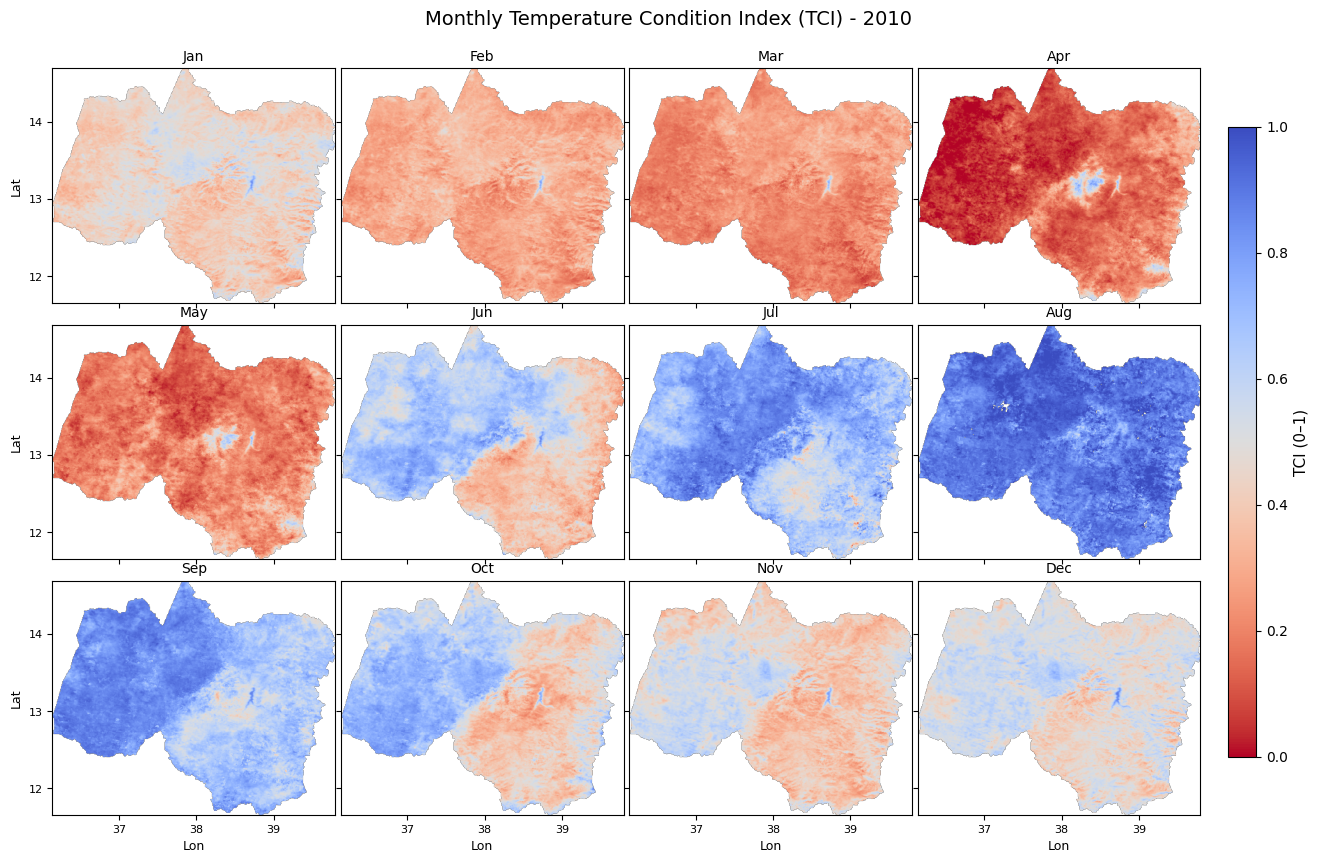

In [11]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ======================
# Folder (TCI outputs)
# ======================
folder = r"C:\Users\gerii\Documents\projects\tekeze\TCI"

files = sorted([
    f for f in os.listdir(folder)
    if f.startswith("TCI_2010") and f.endswith(".tif")
])

print("Files found:", len(files))

# ======================
# Figure
# ======================
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
axes = axes.flatten()

months = ["Jan","Feb","Mar","Apr","May","Jun",
          "Jul","Aug","Sep","Oct","Nov","Dec"]

# ======================
# TCI range (FIXED)
# ======================
vmin = 0
vmax = 1

# ======================
# Plot loop
# ======================
for i, f in enumerate(files):

    path = os.path.join(folder, f)

    with rasterio.open(path) as src:
        data = src.read(1).astype("float32")

        # mask invalid
        data[(data < 0) | (data > 1)] = np.nan

        bounds = src.bounds
        extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]

    ax = axes[i]

    im = ax.imshow(
        data,
        extent=extent,
        origin="upper",
        cmap="coolwarm_r",   # low TCI (stress) = red
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(months[i], fontsize=10)

    # ======================
    # 1-degree ticks
    # ======================
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.tick_params(labelsize=8)

    # ======================
    # Axis control
    # ======================
    row = i // 4
    col = i % 4

    if col == 0:
        ax.set_ylabel("Lat", fontsize=9)
    else:
        ax.set_yticklabels([])

    if row == 2:
        ax.set_xlabel("Lon", fontsize=9)
    else:
        ax.set_xticklabels([])

# ======================
# Remove unused axes
# ======================
for j in range(len(files), 12):
    axes[j].axis("off")

# ======================
# Tight layout
# ======================
plt.subplots_adjust(
    left=0.06,
    right=0.88,
    top=0.92,
    bottom=0.08,
    wspace=0.02,
    hspace=0.05
)

# ======================
# Colorbar (FIXED LABEL)
# ======================
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("TCI (0–1)", fontsize=11)

# ======================
# Title
# ======================
plt.suptitle("Monthly Temperature Condition Index (TCI) - 2010", fontsize=14)

# ======================
# Save
# ======================
fig.canvas.draw()
fig.savefig(
    r"C:\Users\gerii\Documents\projects\tekeze\TCI\TCI_2010_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

### ZLST

In [1]:
import os
import numpy as np
import rasterio
from collections import defaultdict

# ======================
# Input / Output folders
# ======================
in_folder = r"C:\Users\gerii\Documents\projects\tekeze\LST"
out_folder = r"C:\Users\gerii\Documents\projects\tekeze\ZLST"

os.makedirs(out_folder, exist_ok=True)

# ======================
# Collect files
# ======================
files = [
    f for f in os.listdir(in_folder)
    if f.startswith("LST_") and f.endswith(".tif")
]

files = sorted(files)

print("Total files:", len(files))

# ======================
# Group by month
# ======================
monthly_data = defaultdict(list)
monthly_files = defaultdict(list)

meta = None

for f in files:
    # Expected format: LST_YYYY_MM.tif
    parts = f.replace(".tif", "").split("_")
    year = int(parts[1])
    month = int(parts[2])

    path = os.path.join(in_folder, f)

    with rasterio.open(path) as src:
        arr = src.read(1).astype("float32")

        # mask invalid values
        arr[arr < -50] = np.nan

        monthly_data[month].append(arr)
        monthly_files[month].append(f)

        if meta is None:
            meta = src.meta.copy()

print("Grouping by month done ✔")

# ======================
# Compute monthly climatology
# ======================
monthly_mean = {}
monthly_std = {}

for m in range(1, 13):

    stack = np.array(monthly_data[m])  # (time, rows, cols)

    monthly_mean[m] = np.nanmean(stack, axis=0)
    monthly_std[m] = np.nanstd(stack, axis=0)

    # avoid division errors
    monthly_std[m][monthly_std[m] == 0] = np.nan

    print(f"Month {m}: computed mean & std")

# ======================
# Output metadata
# ======================
meta.update(dtype="float32", count=1)

# ======================
# Compute ZLST per file
# ======================
for f in files:

    parts = f.replace(".tif", "").split("_")
    month = int(parts[2])

    path = os.path.join(in_folder, f)

    with rasterio.open(path) as src:
        lst = src.read(1).astype("float32")

        lst[lst < -50] = np.nan

    zlst = (lst - monthly_mean[month]) / monthly_std[month]

    out_name = f.replace("LST_", "ZLST_")
    out_path = os.path.join(out_folder, out_name)

    with rasterio.open(out_path, "w", **meta) as dst:
        dst.write(zlst.astype("float32"), 1)

    print("Saved:", out_name)

print("All monthly ZLST files created successfully ✔")

Total files: 311
Grouping by month done ✔


C:\Users\geri geri\AppData\Local\Temp\ipykernel_8864\1461449162.py:66: RuntimeWarning: Mean of empty slice
  monthly_mean[m] = np.nanmean(stack, axis=0)
C:\Users\gerii\miniconda1\envs\envgg\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Month 1: computed mean & std
Month 2: computed mean & std
Month 3: computed mean & std
Month 4: computed mean & std
Month 5: computed mean & std
Month 6: computed mean & std
Month 7: computed mean & std
Month 8: computed mean & std
Month 9: computed mean & std
Month 10: computed mean & std
Month 11: computed mean & std
Month 12: computed mean & std
Saved: ZLST_2000_02.tif
Saved: ZLST_2000_03.tif
Saved: ZLST_2000_04.tif
Saved: ZLST_2000_05.tif
Saved: ZLST_2000_06.tif
Saved: ZLST_2000_07.tif
Saved: ZLST_2000_08.tif
Saved: ZLST_2000_09.tif
Saved: ZLST_2000_10.tif
Saved: ZLST_2000_11.tif
Saved: ZLST_2000_12.tif
Saved: ZLST_2001_01.tif
Saved: ZLST_2001_02.tif
Saved: ZLST_2001_03.tif
Saved: ZLST_2001_04.tif
Saved: ZLST_2001_05.tif
Saved: ZLST_2001_06.tif
Saved: ZLST_2001_07.tif
Saved: ZLST_2001_08.tif
Saved: ZLST_2001_09.tif
Saved: ZLST_2001_10.tif
Saved: ZLST_2001_11.tif
Saved: ZLST_2001_12.tif
Saved: ZLST_2002_01.tif
Saved: ZLST_2002_02.tif
Saved: ZLST_2002_03.tif
Saved: ZLST_2002_04.tif
S

Files found: 12


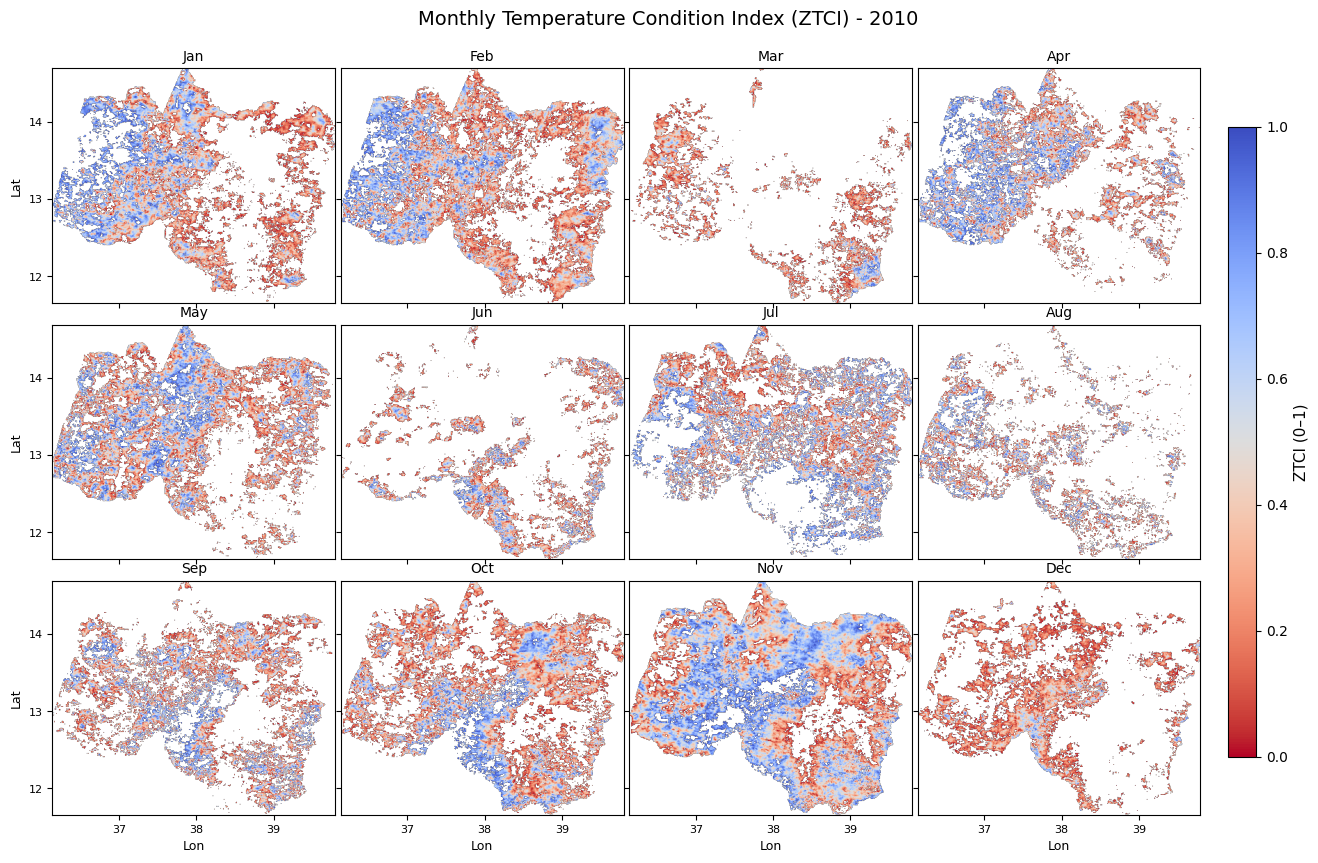

In [4]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ======================
# Folder (TCI outputs)
# ======================
folder = r"C:\Users\gerii\Documents\projects\tekeze\ZLST"

files = sorted([
    f for f in os.listdir(folder)
    if f.startswith("ZLST_2010") and f.endswith(".tif")
])

print("Files found:", len(files))

# ======================
# Figure
# ======================
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
axes = axes.flatten()

months = ["Jan","Feb","Mar","Apr","May","Jun",
          "Jul","Aug","Sep","Oct","Nov","Dec"]

# ======================
# TCI range (FIXED)
# ======================
vmin = 0
vmax = 1

# ======================
# Plot loop
# ======================
for i, f in enumerate(files):

    path = os.path.join(folder, f)

    with rasterio.open(path) as src:
        data = src.read(1).astype("float32")

        # mask invalid
        data[(data < 0) | (data > 1)] = np.nan

        bounds = src.bounds
        extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]

    ax = axes[i]

    im = ax.imshow(
        data,
        extent=extent,
        origin="upper",
        cmap="coolwarm_r",   # low TCI (stress) = red
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(months[i], fontsize=10)

    # ======================
    # 1-degree ticks
    # ======================
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.tick_params(labelsize=8)

    # ======================
    # Axis control
    # ======================
    row = i // 4
    col = i % 4

    if col == 0:
        ax.set_ylabel("Lat", fontsize=9)
    else:
        ax.set_yticklabels([])

    if row == 2:
        ax.set_xlabel("Lon", fontsize=9)
    else:
        ax.set_xticklabels([])

# ======================
# Remove unused axes
# ======================
for j in range(len(files), 12):
    axes[j].axis("off")

# ======================
# Tight layout
# ======================
plt.subplots_adjust(
    left=0.06,
    right=0.88,
    top=0.92,
    bottom=0.08,
    wspace=0.02,
    hspace=0.05
)

# ======================
# Colorbar (FIXED LABEL)
# ======================
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("ZTCI (0–1)", fontsize=11)

# ======================
# Title
# ======================
plt.suptitle("Monthly Temperature Condition Index (ZTCI) - 2010", fontsize=14)

# ======================
# Save
# ======================
fig.canvas.draw()
fig.savefig(
    r"C:\Users\gerii\Documents\projects\tekeze\ZLST\ZTCI_2010_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()